# Python · Kriging — scikit-learn estimators (`pylibkriging.sklearn`)

**Idea.** `pylibkriging.sklearn` makes `Kriging` a scikit-learn estimator, usable in
pipelines, grid searches and cross-validation.

**Reference.** The native `Kriging` class on the same data (same predictions), and
scikit-learn's estimator conventions.

**Tags.** class: Kriging · compared to: scikit-learn · topic: scikit-learn API

`KrigingRegressor` (the scikit-learn face of `Kriging`) on Hartmann 3:
`fit`/`predict` (scikit-learn conventions), the same predictions as the native
class, `get_params`/`set_params`/`clone`, use inside `Pipeline`,
`GridSearchCV`, `cross_val_score`, and `sample_y`.

In [1]:
# Setup for running this notebook outside the repository (Colab, Binder, a lone copy):
# nothing to do in the repository itself (CI, local runs). Otherwise the repository
# (datasets of data/, helpers of tools/python/gallery.py) is cloned and the released pylibkriging installed.
import importlib
import os
import subprocess
import sys
from pathlib import Path

if not Path("tools/known_issues.csv").is_file():
    if not Path("gallery/tools/known_issues.csv").is_file():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/libKriging/gallery"], check=True)
    os.chdir("gallery")
    try:
        import pylibkriging  # noqa: F401
    except ImportError:
        r = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "pylibkriging"],
                           capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(
                f"pylibkriging could not be installed for Python {sys.version_info.major}.{sys.version_info.minor} "
                "(PyPI has wheels for CPython 3.10 to 3.12 only). On Colab: Runtime > Change runtime version > "
                "2026.07 (Python 3.12), then run again.\n" + r.stderr[-500:])
        importlib.invalidate_caches()
sys.path.insert(0, str(Path("tools/python").resolve()))  # for "import gallery" (tools/python/gallery.py)
print("working directory:", os.getcwd())

working directory: /home/runner/work/gallery/gallery


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pylibkriging as lk

import gallery
from gallery import TESTS, design, compat

suite = gallery.Suite("sklearn-estimators_Kriging_python")
print("pylibkriging", compat.version())

tf = TESTS["hartmann3"]
X, y, Xt, yt = design.dataset(tf, 40, n_test=100, seed=61)


def mean_sd(k, Xn):
    out = k.predict(Xn, return_stdev=True)
    return np.ravel(out[0]), np.ravel(out[1])

pylibkriging 1.2.2


## Installing scikit-learn

With pip, into the kernel's environment, numpy pinned to its installed version
(a package that would downgrade it is not installed: the libKriging extension
is built against it). A package that cannot be installed is skipped, and
reported.

In [3]:
import importlib
import subprocess
import sys

import numpy

for package in ["scikit-learn"]:
    r = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package, f"numpy=={numpy.__version__}"],
                       capture_output=True, text=True)
    print(f"{package}: " + ("installed" if r.returncode == 0 else "NOT installed\n" + r.stderr.strip()[-800:]))
importlib.invalidate_caches()

scikit-learn: installed


## scikit-learn estimators

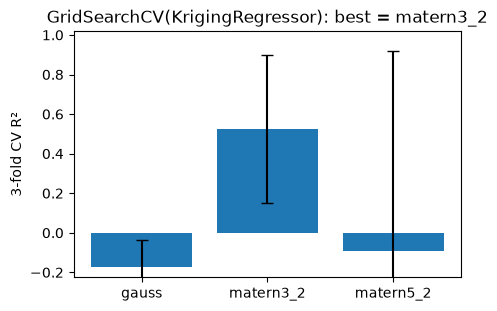

In [4]:
if compat.has("sklearn"):
    from sklearn.base import clone
    from sklearn.model_selection import GridSearchCV, cross_val_score
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import MinMaxScaler
    from pylibkriging.sklearn import KrigingRegressor

    est = KrigingRegressor(kernel="matern5_2").fit(X, y)
    m_sk, s_sk = est.predict(Xt, return_std=True)
    suite.check_true("KrigingRegressor.predict returns 1-D arrays (scikit-learn convention)",
               np.ndim(m_sk) == 1 and np.ndim(s_sk) == 1, detail=f"shapes {np.shape(m_sk)}, {np.shape(s_sk)}",
               severity="warn")
    m_sk, s_sk = np.ravel(m_sk), np.ravel(s_sk)
    m_nat, s_nat = mean_sd(lk.Kriging(y, X, "matern5_2"), Xt)
    suite.check_close("KrigingRegressor == Kriging (mean)", m_sk, m_nat, rtol=1e-8, atol=1e-10)
    suite.check_close("KrigingRegressor == Kriging (stdev)", s_sk, s_nat, rtol=1e-6, atol=1e-10)
    est2 = clone(est).set_params(kernel="gauss")
    suite.check_true("clone + set_params", est2.get_params()["kernel"] == "gauss" and est.get_params()["kernel"] ==
               "matern5_2")
    with suite.check_runs("Pipeline(MinMaxScaler, KrigingRegressor)"):
        pipe = make_pipeline(MinMaxScaler(), KrigingRegressor(kernel="matern5_2")).fit(tf.scale(X), y)
        suite.check_greater("pipeline Q2 on native inputs", pipe.score(tf.scale(Xt), yt), 0.8)
    with suite.check_runs("GridSearchCV over kernels"):
        gs = GridSearchCV(KrigingRegressor(), {"kernel": ["gauss", "matern3_2", "matern5_2"]}, cv=3).fit(X, y)
        suite.check_true("GridSearchCV picked a kernel", gs.best_params_["kernel"] in ("gauss", "matern3_2", "matern5_2"),
                   detail=str(gs.best_params_))
        cv = pd.DataFrame(gs.cv_results_)[["param_kernel", "mean_test_score", "std_test_score", "mean_fit_time"]]
        for _, r in cv.iterrows():
            suite.metric("hartmann3/GridSearchCV", str(r["param_kernel"]), cv_r2=r["mean_test_score"],
                         cv_r2_sd=r["std_test_score"], fit_s=r["mean_fit_time"])
        plt.figure(figsize=(5, 3.2))
        plt.bar(cv["param_kernel"].astype(str), cv["mean_test_score"], yerr=cv["std_test_score"], capsize=4)
        plt.ylabel("3-fold CV R²"); plt.title(f"GridSearchCV(KrigingRegressor): best = {gs.best_params_['kernel']}")
        plt.ylim(min(0, cv["mean_test_score"].min() - .05), 1.02); plt.show()
    with suite.check_runs("cross_val_score"):
        sc = cross_val_score(KrigingRegressor(kernel="matern5_2"), X, y, cv=4)
        suite.check_finite("cross_val_score finite", sc)
    with suite.check_runs("sample_y"):
        S = est.sample_y(Xt[:10], n_samples=5, random_state=1)
        suite.check_true("sample_y shape (q, n_samples)", np.shape(S) == (10, 5), detail=str(np.shape(S)))
else:
    suite.check_skip("sklearn estimators", "pylibkriging.sklearn or scikit-learn not available")

## Summary

The metrics of this notebook, the number of checks per status, and every check that
did not pass (FAIL: error-level, fails the run; WARN: warn-level; KNOWN: listed in
`tools/known_issues.csv`, with its issue; SKIP: feature absent from the installed version).
All of them are also written to `results/sklearn-estimators_Kriging_python.checks.csv` and `.metrics.csv`.

In [5]:
suite.summary()

metric                             cv_r2  cv_r2_sd   fit_s
case                   package                            
hartmann3/GridSearchCV gauss     -0.1754    0.1400  0.0028
                       matern3_2  0.5240    0.3742  0.0031
                       matern5_2 -0.0941    1.0126  0.0036

12 checks: PASS 12, FAIL 0, WARN 0, KNOWN 0, SKIP 0


In [6]:
suite.finalize()

sklearn-estimators_Kriging_python: PASS 12, FAIL 0, WARN 0, KNOWN 0, SKIP 0


{'PASS': 12, 'FAIL': 0, 'WARN': 0, 'KNOWN': 0, 'SKIP': 0}